# Calibrating a classifier under domain shift: galaxy images

A classifier returns, for each image, a probability for each class, and the largest of
these is often read as a statement of confidence. The statement is only useful if it is
*calibrated*: among the images for which the classifier reports a confidence of 0.8, about
80 % should be classified correctly. Neural networks trained with the usual cross-entropy
loss tend to be over-confident, and the problem can become much worse when the network is
applied to data that differ from its training data. This notebook measures that effect on
the galaxy morphology images from the SIDDA data release, with the Sloan Digital Sky Survey
(SDSS) as the training domain and the DESI Legacy Survey as a new domain, and then tests
two ways of recalibrating the probabilities with the `shiftkit.uq` module: temperature
scaling, a standard one-parameter method, and KCal (Lin, Trivedi and Sun, 2022), which
replaces the last layer of the network by a kernel density classifier on its internal
representation.

The questions are quantitative. How over-confident is the network on each survey? How much
of the miscalibration can be removed using only labelled SDSS images, which is the situation
when no labels are available for the new survey? And what changes if a few hundred labelled
DESI images are available? Every number is the mean over eight independent repetitions, each
with its own split of the SDSS images and its own network, with the range over the
repetitions in parentheses, because a single network turns out to be an unreliable basis for
any of these comparisons.

In [ ]:
import warnings; warnings.filterwarnings("ignore")
import contextlib, io, time
import numpy as np, torch
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader, TensorDataset

from shiftkit import GalaxyCNN
from shiftkit.data.galaxy import load_galaxy_subset, CLASSES
from shiftkit.uq import embed
from shiftkit.utils import set_seed

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", DEVICE)

def train_quietly(trainer, epochs):
    # The trainers print one line per epoch; keep the history, suppress the log.
    with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):
        return trainer.fit(epochs=epochs)

Failed to run 'pixi install --environment default':  WARN cache for Repodata at /home/karla/.cache/rattler/cache/repodata is on a network/parallel filesystem (NFS/SMB/FUSE/BeeGFS/Lustre/GPFS/CephFS), redirected to /tmp/pixi-cache-karla/repodata for this run. Set [cache.repodata] in config.toml or PIXI_CACHE_DIR to override, or [cache.netfs-redirect] = "never" to keep the original path.
Error:   × failed to acquire install lock on prefix '/opt/pixi/.pixi/envs/default'
  ╰─▶ Permission denied (os error 13)




## 1. Data

The images come from the Zenodo record that accompanies the SIDDA paper
(doi:10.5281/zenodo.14583107, licence CC BY 4.0). The archive is 2.4 GB compressed and
about 19 GB unpacked, so `load_galaxy_subset` streams only the first rows of each array over
HTTP and caches them as 32-bit floats. These rows are a representative sample because the
arrays are shuffled; the helper checks this against the class proportions of the full label
files. With 3,000 training and 1,000 test images per survey, the first call transfers
roughly 240 MB and takes about eight minutes, and the cache occupies about 960 MB. Later
calls read the cache. Each image has 3 colour channels of 100 by 100 pixels and one of six
morphological classes.

In [2]:
# The first call downloads a subset from Zenodo (about 240 MB over the network, roughly 8 minutes,
# and a cache of about 960 MB on disk). Later calls read the cache and take a second.
N_TRAIN, N_TEST = 3000, 1000
data = load_galaxy_subset(cache_dir="./data/galaxy", n_train=N_TRAIN, n_test=N_TEST)

x_sdss, y_sdss = data["x_train_sdss"], data["y_train_sdss"]
x_desi, y_desi = data["x_train_desi"], data["y_train_desi"]
x_sdss_te, y_sdss_te = data["x_test_sdss"], data["y_test_sdss"]
x_desi_te, y_desi_te = data["x_test_desi"], data["y_test_desi"]

def loader(x, y=None, shuffle=False, batch_size=64):
    tensors = [torch.from_numpy(x)] + ([torch.from_numpy(y)] if y is not None else [])
    return DataLoader(TensorDataset(*tensors), batch_size=batch_size, shuffle=shuffle)

print(f"SDSS: {len(x_sdss)} train, {len(x_sdss_te)} test    DESI: {len(x_desi)} train, {len(x_desi_te)} test")
print("image tensor:", x_sdss.shape[1:], x_sdss.dtype, " mean pixel  SDSS %.3f  DESI %.3f" % (x_sdss.mean(), x_desi.mean()))

SDSS: 3000 train, 1000 test    DESI: 3000 train, 1000 test
image tensor: (3, 100, 100) float32  mean pixel  SDSS 0.037  DESI 0.099


## 2. The two surveys

The figures show one example per class from each survey, brightened by a factor of three
for display only, and the proportion of images in each class. The surveys differ in the
appearance of the images, with a darker and cleaner background in SDSS and a grey, noisier
one in DESI (mean pixel value 0.037 against 0.099), and they also differ in class
proportions. Smooth round galaxies are about half of the DESI images, so a classifier that
always answers "smooth round" would be right 52.6 % of the time there. That value is the
reference against which any accuracy on DESI has to be judged.

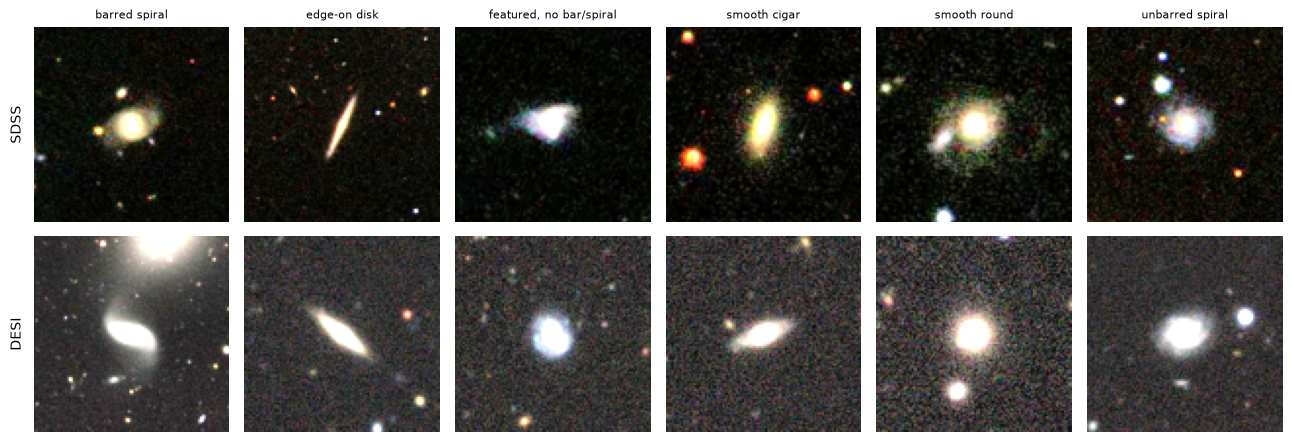

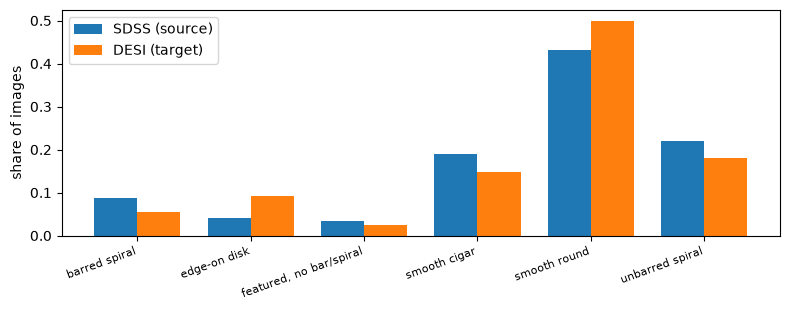

In [3]:
short = ["barred spiral", "edge-on disk", "featured, no bar/spiral", "smooth cigar", "smooth round", "unbarred spiral"]
fig, axes = plt.subplots(2, 6, figsize=(13, 4.6))
for r, (name, x, y) in enumerate((("SDSS", x_sdss, y_sdss), ("DESI", x_desi, y_desi))):
    for k in range(6):
        i = np.flatnonzero(y == k)[0]
        axes[r, k].imshow(np.clip(x[i].transpose(1, 2, 0) * 3, 0, 1)); axes[r, k].axis("off")   # x3 for display only
        if r == 0: axes[r, k].set_title(short[k], fontsize=8)
    axes[r, 0].text(-0.05, 0.5, name, transform=axes[r, 0].transAxes, rotation=90, va="center", ha="right")
plt.tight_layout(); plt.show()

share = lambda y: np.bincount(y, minlength=6) / len(y)
fig, ax = plt.subplots(figsize=(8, 3.2)); w = 0.38; k = np.arange(6)
ax.bar(k - w / 2, share(y_sdss), w, label="SDSS (source)"); ax.bar(k + w / 2, share(y_desi), w, label="DESI (target)")
ax.set_xticks(k); ax.set_xticklabels(short, rotation=20, ha="right", fontsize=8); ax.set_ylabel("share of images"); ax.legend()
plt.tight_layout(); plt.show()

## 3. One repetition of the experiment

The network is the small convolutional network `GalaxyCNN`, trained with cross-entropy on
SDSS images only. The function `repetition` carries out one complete experiment. It divides
the 3,000 SDSS training images at random into 2,100 that train the network and 900 that are
kept for calibration. Calibration must use images the network has not been trained on,
because on its own training images the network is more accurate and more confident than it
will be on new data, and a calibration fitted there would be too optimistic. It then trains
the network, computes the internal representation and the logits for every image set that
will be needed, and evaluates six sets of probabilities on both test sets: the raw softmax;
temperature scaling and KCal calibrated on the 900 SDSS images; and temperature scaling, KCal
and a plain logistic regression fitted on 600 labelled DESI training images, which do not
overlap with the DESI test images. The DESI training images enter the network's training only
as unlabelled inputs that the trainer monitors, and they do not influence the weights.

The helper `embed` returns, for a set of images, the 256-dimensional internal representation
that the network computes before its last layer, the logits, and the labels. KCal works on
the representation, temperature scaling on the logits. The function `set_seed` makes each
repetition reproducible on the same hardware, so that running the notebook again gives the
same numbers.

In [4]:
from sklearn.linear_model import LogisticRegression
from shiftkit import SourceOnlyTrainer
from shiftkit.uq import (KCalibrator, calibration_report, fit_temperature, reliability_curve, softmax_np)

LR, EPOCHS = 1e-2, 30
N_FIT, N_LABELS = 2100, 600          # 2,100 SDSS images train the network, the other 900 calibrate; 600 labelled DESI images for section 6
emb = lambda model, x, y: embed(model, loader(x, y, batch_size=256))

def repetition(seed):
    # One complete experiment: split the SDSS images, train a network, and evaluate every calibration option.
    set_seed(seed)
    perm = np.random.default_rng(seed).permutation(len(x_sdss))
    fit_idx, cal_idx = perm[:N_FIT], perm[N_FIT:]                  # the test sets stay untouched
    model = GalaxyCNN()
    trainer = SourceOnlyTrainer(model, loader(x_sdss[fit_idx], y_sdss[fit_idx], True),
                                loader(x_desi, y_desi, True), lr=LR, device=DEVICE)   # DESI inputs are only monitored, never trained on
    train_quietly(trainer, EPOCHS)
    z_fit, _, y_fit = emb(model, x_sdss[fit_idx], y_sdss[fit_idx])
    z_cal, lg_cal, y_cal = emb(model, x_sdss[cal_idx], y_sdss[cal_idx])
    z_tl, lg_tl, y_tl = emb(model, x_desi[:N_LABELS], y_desi[:N_LABELS])   # labelled DESI training images, disjoint from the DESI test set
    test = {"source": emb(model, x_sdss_te, y_sdss_te), "target": emb(model, x_desi_te, y_desi_te)}

    T, T_t = fit_temperature(lg_cal, y_cal), fit_temperature(lg_tl, y_tl)
    kcal = KCalibrator(n_classes=6, n_iters=400, seed=seed).fit(z_fit, y_fit).calibrate(z_cal, y_cal)
    kcal_t = KCalibrator(n_classes=6, n_iters=400, seed=seed).fit(z_fit, y_fit).calibrate(z_tl, y_tl)
    head = LogisticRegression(max_iter=3000).fit(z_tl, y_tl)

    out = {"model": model, "test": test, "T": T}
    for name, (z, lg, y) in test.items():
        p_head = np.zeros((len(y), 6)); p_head[:, head.classes_] = head.predict_proba(z)
        out[name] = {"softmax": softmax_np(lg), "temperature (SDSS labels)": softmax_np(lg / T), "KCal (SDSS labels)": kcal.predict_proba(z),
                     "temperature (DESI labels)": softmax_np(lg / T_t), "KCal (DESI labels)": kcal_t.predict_proba(z), "logistic head (DESI labels)": p_head}
        out[name + "_y"] = y
    return out

## 4. Eight repetitions

The cell below runs eight repetitions, seeds 0 to 7, which takes a few minutes on a GPU and
several times longer on a CPU. The network accuracy on the two test sets is printed for each
seed. On the SDSS test images the networks are consistent, with accuracies between 0.62 and
0.70. On the DESI test images they are not: the accuracy ranges from 0.08 to 0.52, and
in every seed it is below the 0.526 that the constant majority-class answer achieves.

In [5]:
SEEDS = list(range(8))
runs = []
for seed in SEEDS:
    t0 = time.time(); runs.append(repetition(seed))
    r = calibration_report(runs[-1]["target"]["softmax"], runs[-1]["target_y"])
    print(f"seed {seed}: network accuracy  SDSS test {calibration_report(runs[-1]['source']['softmax'], runs[-1]['source_y'])['accuracy']:.3f}   "
          f"DESI test {r['accuracy']:.3f}   ({time.time() - t0:.0f} s)")

KEYS = ("accuracy", "brier", "log_loss", "ece_conf", "ece_classwise")
def table(domain, methods):
    print(f"{'':30s} {'accuracy':>16s} {'Brier':>16s} {'ECE':>16s} {'class-wise ECE':>16s}")
    for m in methods:
        vals = {k: np.array([calibration_report(r[domain][m], r[domain + "_y"])[k] for r in runs]) for k in KEYS}
        cell = lambda k: f"{vals[k].mean():.3f} ({vals[k].min():.2f}-{vals[k].max():.2f})".rjust(16)
        print(f"{m:30s} {cell('accuracy')} {cell('brier')} {cell('ece_conf')} {cell('ece_classwise')}")

seed 0: network accuracy  SDSS test 0.616   DESI test 0.215   (27 s)


seed 1: network accuracy  SDSS test 0.696   DESI test 0.519   (25 s)


seed 2: network accuracy  SDSS test 0.690   DESI test 0.447   (28 s)


seed 3: network accuracy  SDSS test 0.633   DESI test 0.510   (27 s)


seed 4: network accuracy  SDSS test 0.655   DESI test 0.283   (27 s)


seed 5: network accuracy  SDSS test 0.653   DESI test 0.250   (27 s)


seed 6: network accuracy  SDSS test 0.674   DESI test 0.080   (27 s)


seed 7: network accuracy  SDSS test 0.638   DESI test 0.279   (25 s)


## 5. How over-confident is the softmax?

Five numbers summarise a set of probability forecasts. The accuracy is the fraction of
correct top-class predictions. The Brier score is the mean squared distance between the
probability vector and the one-hot label, and the log loss is the mean negative log
probability of the true class; both are *proper scoring rules*, which reward honest
probabilities, and lower is better. The expected calibration error (ECE) is the average
gap between the confidence and the accuracy in bins of confidence, weighted by the
number of images in the bin. The class-wise ECE applies the same idea to every class
separately and averages, which tests the probability given to each class and not only to
the most probable one.

On the SDSS test images the networks are correct for 66 % of the images on average, and the
ECE is 0.23, so they are over-confident even on the domain they were trained for. On the DESI
test images the mean accuracy falls to 32 % and the ECE rises to 0.47. In the reliability
diagrams, the dashed diagonal is perfect calibration. The eight curves for SDSS lie together,
below the diagonal, whereas those for DESI are scattered and, in most seeds, flat at accuracies between
about 0.05 and 0.4 for confidences from 0.4 to 1, so that in several seeds the confidence of
the network on this survey says very little about whether a particular prediction is right.
That is a stronger failure than a systematic over-estimate, and no recalibration that only
rescales the confidences can fix a flat curve. Only bins with at least ten images are drawn.

SDSS test images (the training domain), mean over seeds with the range in parentheses
                                       accuracy            Brier              ECE   class-wise ECE
softmax                        0.657 (0.62-0.70) 0.560 (0.50-0.61) 0.234 (0.19-0.26) 0.086 (0.07-0.09)

DESI test images
                                       accuracy            Brier              ECE   class-wise ECE
softmax                        0.323 (0.08-0.52) 1.065 (0.81-1.55) 0.467 (0.28-0.76) 0.182 (0.13-0.27)

majority-class rate on the DESI test set: 0.526


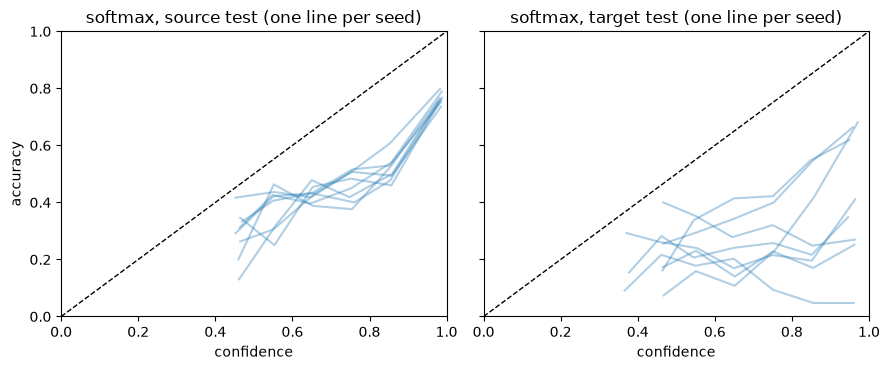

In [6]:
print("SDSS test images (the training domain), mean over seeds with the range in parentheses")
table("source", ["softmax"])
print("\nDESI test images")
table("target", ["softmax"])
print("\nmajority-class rate on the DESI test set: %.3f" % (np.bincount(y_desi_te).max() / len(y_desi_te)))

fig, axes = plt.subplots(1, 2, figsize=(9, 3.8), sharey=True)
for ax, name in zip(axes, ("source", "target")):
    for r in runs:
        c = reliability_curve(r[name]["softmax"], r[name + "_y"], bins=10); ok = c["count"] >= 10
        ax.plot(c["confidence"][ok], c["accuracy"][ok], "-", color="tab:blue", alpha=0.35)
    ax.plot([0, 1], [0, 1], "k--", lw=1); ax.set_title(f"softmax, {name} test (one line per seed)"); ax.set_xlabel("confidence"); ax.set_xlim(0, 1); ax.set_ylim(0, 1)
axes[0].set_ylabel("accuracy"); plt.tight_layout(); plt.show()

## 6. Recalibrating with labelled SDSS images

Temperature scaling divides the logits by a single number $T$ before the softmax, choosing
$T$ to minimise the log loss on the calibration images. It never changes which class is
predicted, so the accuracy is unchanged. KCal replaces the last layer entirely. It learns a
projection of the 256-dimensional representation into a smaller space (here 32 dimensions)
by training a kernel density classifier on the network's training images, with each training
image classified against a class-balanced sample of the others and never against itself, and
then it predicts the probability of a class as the kernel-weighted share of the
*calibration* images of that class near the test image. The kernel bandwidth is chosen on the
calibration images by leave-one-out log loss. The method is a compact re-implementation of
the one in the paper, and the paper's guarantee of calibration holds when the calibration
images come from the same distribution as the images being predicted. A query that is far
from every calibration image receives the class frequencies of the calibration set.

In [7]:
print("calibrated with the 900 held-out SDSS images; no DESI labels are used")
for name in ("source", "target"):
    print(f"\n{name.upper() if name == 'source' else 'DESI'} test images")
    table(name, ["softmax", "temperature (SDSS labels)", "KCal (SDSS labels)"])
print("\ntemperatures fitted on SDSS:", np.round([r["T"] for r in runs], 2))
better = sum(calibration_report(r["target"]["KCal (SDSS labels)"], r["target_y"])["brier"] < calibration_report(r["target"]["temperature (SDSS labels)"], r["target_y"])["brier"] for r in runs)
print(f"on DESI, KCal has the lower Brier score than temperature scaling in {better} of {len(runs)} seeds")

calibrated with the 900 held-out SDSS images; no DESI labels are used

SOURCE test images
                                       accuracy            Brier              ECE   class-wise ECE
softmax                        0.657 (0.62-0.70) 0.560 (0.50-0.61) 0.234 (0.19-0.26) 0.086 (0.07-0.09)
temperature (SDSS labels)      0.657 (0.62-0.70) 0.471 (0.42-0.53) 0.050 (0.03-0.06) 0.050 (0.04-0.06)


KCal (SDSS labels)             0.701 (0.68-0.72) 0.424 (0.40-0.45) 0.049 (0.02-0.08) 0.031 (0.03-0.04)

DESI test images
                                       accuracy            Brier              ECE   class-wise ECE
softmax                        0.323 (0.08-0.52) 1.065 (0.81-1.55) 0.467 (0.28-0.76) 0.182 (0.13-0.27)
temperature (SDSS labels)      0.323 (0.08-0.52) 0.791 (0.67-0.94) 0.178 (0.07-0.36) 0.129 (0.09-0.16)
KCal (SDSS labels)             0.472 (0.35-0.55) 0.696 (0.63-0.76) 0.101 (0.06-0.16) 0.096 (0.07-0.12)

temperatures fitted on SDSS: [3.47 3.59 3.09 3.76 3.67 4.09 4.13 4.43]


on DESI, KCal has the lower Brier score than temperature scaling in 8 of 8 seeds


On the SDSS test images both methods remove most of the miscalibration (ECE 0.050 and 0.049,
from 0.234), and KCal also gives the lower Brier score (0.424 against 0.471) and a higher
accuracy (0.701 against 0.657), because its kernel classifier uses the representation more
effectively than the original last layer. On the DESI test images both methods improve on the
raw softmax, but the improvement is partial: the ECE falls from 0.467 to 0.178 for temperature
scaling and to 0.101 for KCal, and the Brier score from 1.065 to 0.791 and 0.696. KCal has the
lower Brier score in each of the eight repetitions, and its accuracy on DESI is 0.472 against
0.323 for the original network. The gain over temperature scaling is therefore consistent.
It is also incomplete. Both methods were calibrated on SDSS images, which are not distributed
like the DESI test images, so the guarantee of the method does not apply, and the ECE of 0.10
that remains for KCal is about twice the value it reaches on SDSS. The reliability diagrams
show one repetition: the curve for KCal lies closest to the diagonal, with that for
temperature scaling below it, and the raw softmax flat near 0.2. The last bins of each curve
contain few images, so the figure illustrates the average result and does not establish it.

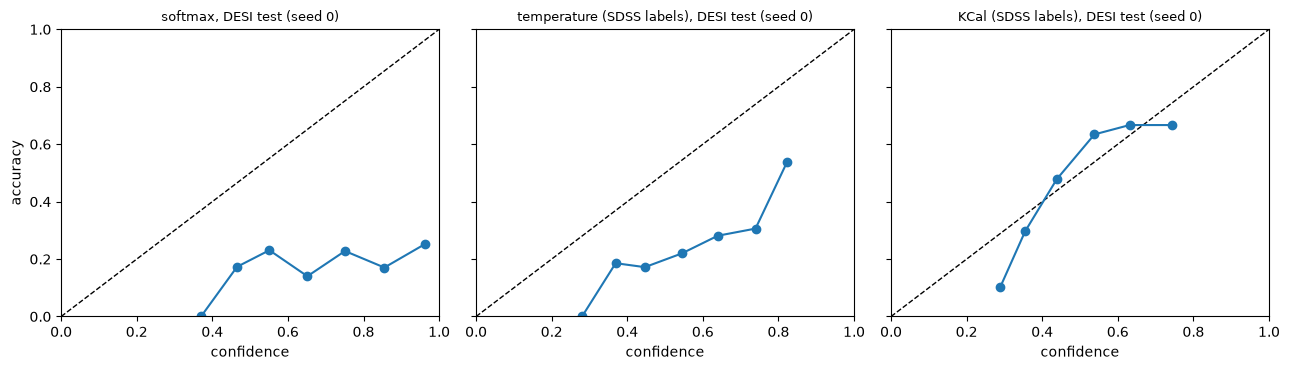

In [8]:
run0 = runs[0]
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
for ax, m in zip(axes, ("softmax", "temperature (SDSS labels)", "KCal (SDSS labels)")):
    c = reliability_curve(run0["target"][m], run0["target_y"], bins=10); ok = c["count"] > 0
    ax.plot([0, 1], [0, 1], "k--", lw=1); ax.plot(c["confidence"][ok], c["accuracy"][ok], "o-")
    ax.set_title(f"{m}, DESI test (seed 0)", fontsize=9); ax.set_xlabel("confidence"); ax.set_xlim(0, 1); ax.set_ylim(0, 1)
axes[0].set_ylabel("accuracy"); plt.tight_layout(); plt.show()

## 7. A few labelled images from the new survey

The remaining option is to calibrate on labelled images from the survey where the network
will be used. The cell below uses the first 600 labelled DESI training images in place of the
SDSS calibration images. The logistic regression is a reference and not a calibration method:
it ignores the network's last layer and fits a new linear classifier to the same 600 labelled
representations, which shows how much of any improvement is due to the labels and not to the
calibration procedure. The second table evaluates the same three DESI-calibrated procedures on
the SDSS test images.

In [9]:
print(f"calibration / fitting data: the first {N_LABELS} labelled DESI training images (disjoint from the DESI test set)\n")
print("DESI test images")
table("target", ["softmax", "temperature (DESI labels)", "KCal (DESI labels)", "logistic head (DESI labels)"])
print("\nthe same calibrators evaluated on the SDSS test images")
table("source", ["softmax", "temperature (DESI labels)", "KCal (DESI labels)", "logistic head (DESI labels)"])

calibration / fitting data: the first 600 labelled DESI training images (disjoint from the DESI test set)

DESI test images
                                       accuracy            Brier              ECE   class-wise ECE


softmax                        0.323 (0.08-0.52) 1.065 (0.81-1.55) 0.467 (0.28-0.76) 0.182 (0.13-0.27)
temperature (DESI labels)      0.323 (0.08-0.52) 0.760 (0.71-0.82) 0.124 (0.05-0.21) 0.121 (0.11-0.13)
KCal (DESI labels)             0.581 (0.55-0.62) 0.569 (0.54-0.61) 0.080 (0.04-0.11) 0.038 (0.03-0.05)


logistic head (DESI labels)    0.647 (0.63-0.66) 0.493 (0.48-0.51) 0.059 (0.05-0.09) 0.032 (0.03-0.04)

the same calibrators evaluated on the SDSS test images
                                       accuracy            Brier              ECE   class-wise ECE


softmax                        0.657 (0.62-0.70) 0.560 (0.50-0.61) 0.234 (0.19-0.26) 0.086 (0.07-0.09)
temperature (DESI labels)      0.657 (0.62-0.70) 0.579 (0.53-0.66) 0.269 (0.19-0.36) 0.109 (0.08-0.13)


KCal (DESI labels)             0.322 (0.17-0.43) 1.071 (0.79-1.36) 0.439 (0.19-0.60) 0.167 (0.11-0.23)


logistic head (DESI labels)    0.444 (0.29-0.60) 0.908 (0.61-1.19) 0.393 (0.14-0.56) 0.157 (0.09-0.21)


The labels make a large difference on DESI. Temperature scaling calibrated on 600 DESI images
reaches an ECE of 0.124, but it does so by lowering the confidence of networks that are wrong
most of the time, and the accuracy stays at 0.323. A classifier can be calibrated and still
be of little use, so the ECE has to be read together with the accuracy and the Brier score.
KCal raises the accuracy to 0.581 and lowers the Brier score from 0.760 to 0.569, and its
class-wise ECE of 0.038 is much lower than that of temperature scaling (0.121), so the
probabilities given to each class are better. The plain logistic regression on the same 600
labelled representations does better still (accuracy 0.647, Brier score 0.493, ECE 0.059).
A large part of the benefit shown here therefore comes from having labelled images of the new
survey at all, and KCal is not better than refitting a linear classifier with those labels.
Its role is to improve the probabilities of a network that is kept fixed.

The second table shows that calibration does not carry over from one survey to the other in
either direction. Procedures calibrated on DESI images perform badly on the SDSS test images:
KCal falls to an accuracy of 0.322 and an ECE of 0.439, worse than the raw softmax (0.657 and
0.234), and the logistic regression to 0.444 and 0.393. Temperature scaling keeps the accuracy of the
raw softmax, because it cannot change the predicted class, but its ECE (0.269) and Brier score
(0.579) are slightly worse than before calibration.

## 8. Scope and limitations

The results come from one small convolutional network, a subset of the data (3,000 training
images per survey) and eight repetitions. The ranges reported are the minimum and maximum over
these eight, and they are not confidence intervals. The network is also unusually poor on DESI,
so the absolute numbers say little about better models. The ECE depends on the number of bins,
15 here, and on the number of images, and a class-wise ECE is only a proxy for the full
calibration that the paper targets. The paper's guarantee is asymptotic and does not cover a
shift of the input distribution, which is why calibrating on SDSS did not carry over to DESI.
In an earlier version of the KCal implementation, evaluating a calibrator on images far from
its calibration set could return probabilities that did not sum to one, which this
many-repetition experiment exposed; that has been corrected and is covered by a test.

**References.** Lin, Trivedi and Sun (2022), *Taking a Step Back with KCal: Multi-Class
Kernel-Based Calibration for Deep Neural Networks*, arXiv:2202.07679. Guo, Pleiss, Sun and
Weinberger (2017), *On Calibration of Modern Neural Networks*, ICML, for temperature
scaling. Pandya, Patel, Nord, Walmsley and Ćiprijanović (2025), *Machine Learning: Science
and Technology* 6(3), 035032, for the data.